# Issue 7: Análisis de componentes principales (PCA)

Continúa [issue6.ipynb](issue6.ipynb) (carga su checkpoint o, si no existe, ejecuta la cadena). Recibe `X_train`, `y_train`, `X_val`, `y_val`, `X_test` y `y_test` con los nulos imputados por el Issue 5, sus indicadores `<columna>_nulo`, y las numéricas winsorizadas, con `log1p` en las asimétricas y escaladas con `StandardScaler` por el Issue 6.

**Objetivo:** decidir si conviene reemplazar las variables numéricas por componentes principales antes del modelado. PCA no mira el target: busca las direcciones de mayor varianza, que no tienen por qué ser las que mejor separan `Charged Off`.

**Reglas:** PCA se ajusta solo con entrenamiento; las comparaciones se hacen en validación; el conjunto de prueba no se usa. `issue_d` no entra, porque la propuesta no lo admite como predictor.

In [1]:
# Carga el checkpoint de issue6 (data/checkpoints/issue6/) en lugar de ejecutar toda la cadena.
# Si no existe, se ejecuta issue6.ipynb, que lo genera al terminar.
import sys
sys.path.append('..')
from src.checkpoints import cargar_checkpoint, existe_checkpoint

if existe_checkpoint('issue6'):
    globals().update(cargar_checkpoint('issue6'))
else:
    %run issue6.ipynb

Checkpoint issue6 cargado: X_train (862757, 117), X_val (215690, 117), X_test (269612, 117), y_train (862757,), y_val (215690,), y_test (269612,)


In [2]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

sys.path.append(str(Path.cwd().parent))
from src.data import COLUMNA_FECHA, SEED

pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 120)

DIR_FIGURAS = Path.cwd().parent / 'reports' / 'figures'
AZUL, NARANJA, TINTA, TINTA_2, REJILLA = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.edgecolor': TINTA_2,
    'axes.labelcolor': TINTA, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
})

def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / nombre, dpi=150, bbox_inches='tight')
    print(f'Figura guardada en reports/figures/{nombre}')

## 1. Datos de la cadena

La cadena entrega 109 columnas numéricas: **61 variables continuas** y **48 indicadores** `<columna>_nulo` creados por el Issue 5. Las categóricas (`term`, `purpose`, `addr_state`, etc.) aún no están codificadas y no entran: la codificación no es parte de este issue.

Decisiones sobre la entrada del PCA:

- **PCA se ajusta sobre las 61 continuas.** Los indicadores son binarios (0/1 antes de escalar): PCA resume varianza de variables continuas y no aporta una lectura útil sobre banderas de nulo.
- **Los indicadores se deduplican.** El Issue 6 advierte que de los 48 solo 24 son distintos, porque bloques enteros de columnas comparten el patrón de nulos. Se deja uno por grupo de copias exactas (detectadas en entrenamiento) y esos indicadores únicos pasan **sin PCA** al lado de los componentes.
- Como control, la sección 5 también ajusta PCA sobre las continuas más los indicadores únicos.

Antes de ajustar se comprueba lo que PCA necesita: sin `issue_d`, sin nulos y con varianza 1 en todas las columnas. Si una columna tuviera más varianza que el resto, dominaría los primeros componentes solo por su escala.

In [3]:
numericas_cadena = list(X_train.select_dtypes('number').columns)
categoricas = [c for c in X_train.columns if c not in numericas_cadena]
indicadores = [c for c in numericas_cadena if c.endswith('_nulo')]
continuas = [c for c in numericas_cadena if c not in indicadores]

# Grupos de indicadores idénticos en entrenamiento; se conserva el primero de cada grupo
grupos_indicadores = {}
for col in indicadores:
    valores = X_train[col].to_numpy()
    for repr_ in grupos_indicadores:
        if np.array_equal(valores, X_train[repr_].to_numpy()):
            grupos_indicadores[repr_].append(col)
            break
    else:
        grupos_indicadores[col] = [col]
indicadores_unicos = list(grupos_indicadores)
for repr_, grupo in grupos_indicadores.items():  # las copias también coinciden en validación
    assert all(np.array_equal(X_val[repr_].to_numpy(), X_val[c].to_numpy()) for c in grupo)

X_ent = X_train[continuas]      # nombres de trabajo, sin pisar los de la cadena
X_val_num = X_val[continuas]
I_ent = X_train[indicadores_unicos].to_numpy()
I_val = X_val[indicadores_unicos].to_numpy()

assert COLUMNA_FECHA not in X_train.columns, 'issue_d no puede entrar al PCA'
assert X_train[numericas_cadena].isna().sum().sum() == 0 and X_val[numericas_cadena].isna().sum().sum() == 0
desv = X_ent.std()
assert np.allclose(desv, 1, atol=1e-3) and np.allclose(X_ent.mean(), 0, atol=1e-6)

print(f'Numéricas de la cadena: {len(numericas_cadena)} = {len(continuas)} continuas + {len(indicadores)} indicadores de nulo')
print(f'Indicadores distintos: {len(indicadores_unicos)}; categóricas fuera del PCA: {len(categoricas)} {categoricas}')
print(f'Entrenamiento: {X_ent.shape}; validación: {X_val_num.shape}')
print(f'Desviaciones de las continuas en entrenamiento: [{desv.min():.4f}, {desv.max():.4f}]')
print('\nGrupos de indicadores con copias exactas (se conserva el primero):')
for repr_, grupo in grupos_indicadores.items():
    if len(grupo) > 1:
        print(f'  {len(grupo):>2}: {repr_} <- {", ".join(grupo[1:])}')

Numéricas de la cadena: 109 = 61 continuas + 48 indicadores de nulo
Indicadores distintos: 24; categóricas fuera del PCA: 8 ['term', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'earliest_cr_line', 'application_type']
Entrenamiento: (862757, 61); validación: (215690, 61)
Desviaciones de las continuas en entrenamiento: [1.0000, 1.0000]

Grupos de indicadores con copias exactas (se conserva el primero):
   2: mo_sin_old_rev_tl_op_nulo <- mo_sin_rcnt_rev_tl_op_nulo
  13: tot_coll_amt_nulo <- num_accts_ever_120_pd_nulo, tot_hi_cred_lim_nulo, num_tl_op_past_12m_nulo, num_tl_90g_dpd_24m_nulo, num_op_rev_tl_nulo, num_il_tl_nulo, num_bc_tl_nulo, num_actv_rev_tl_nulo, num_actv_bc_tl_nulo, total_il_high_credit_limit_nulo, total_rev_hi_lim_nulo, mo_sin_rcnt_tl_nulo
   4: mort_acc_nulo <- total_bc_limit_nulo, total_bal_ex_mort_nulo, acc_open_past_24mths_nulo
   3: open_acc_6m_nulo <- inq_last_12m_nulo, total_cu_tl_nulo
   7: inq_fi_nulo <- open_il_24m_nulo, open_

## 2. Varianza explicada

Se ajusta PCA con todos los componentes, solo con entrenamiento, para ver cómo se reparte la varianza. Se usan dos criterios habituales para elegir el número de componentes:

- **Varianza acumulada:** el menor número de componentes que alcanza 80 %, 90 %, 95 % o 99 %.
- **Criterio de Kaiser:** conservar los componentes con autovalor mayor que 1, es decir, los que explican más varianza que una variable original estandarizada.

In [4]:
pca = PCA(random_state=SEED).fit(X_ent)
nombres_pc = [f'PC{i + 1}' for i in range(pca.n_components_)]
varianza = pd.DataFrame({
    'autovalor': pca.explained_variance_,
    'varianza_%': pca.explained_variance_ratio_ * 100,
    'acumulada_%': pca.explained_variance_ratio_.cumsum() * 100,
}, index=nombres_pc)

UMBRALES = (80, 90, 95, 99)
componentes_para = {u: int(np.searchsorted(varianza['acumulada_%'].values, u) + 1) for u in UMBRALES}
kaiser = int((varianza['autovalor'] > 1).sum())

print('Componentes necesarios por varianza acumulada:')
for u, k in componentes_para.items():
    print(f'  {u} % -> {k} de {len(continuas)}')
print(f'Criterio de Kaiser (autovalor > 1): {kaiser} componentes, {varianza["acumulada_%"].iloc[kaiser - 1]:.1f} % de la varianza')
varianza.head(12).round(3)

Componentes necesarios por varianza acumulada:
  80 % -> 22 de 61
  90 % -> 32 de 61
  95 % -> 41 de 61
  99 % -> 53 de 61
Criterio de Kaiser (autovalor > 1): 17 componentes, 73.5 % de la varianza


,autovalor,varianza_%,acumulada_%
PC1,9.005,14.762,14.762
PC2,5.434,8.908,23.670
PC3,4.897,8.027,31.697
PC4,3.765,6.171,37.869
PC5,3.353,5.497,43.366
PC6,2.554,4.187,47.553
PC7,2.213,3.627,51.180
PC8,1.933,3.169,54.349
PC9,1.858,3.045,57.394
PC10,1.505,2.468,59.862


Figura guardada en reports/figures/pca_varianza_explicada.png


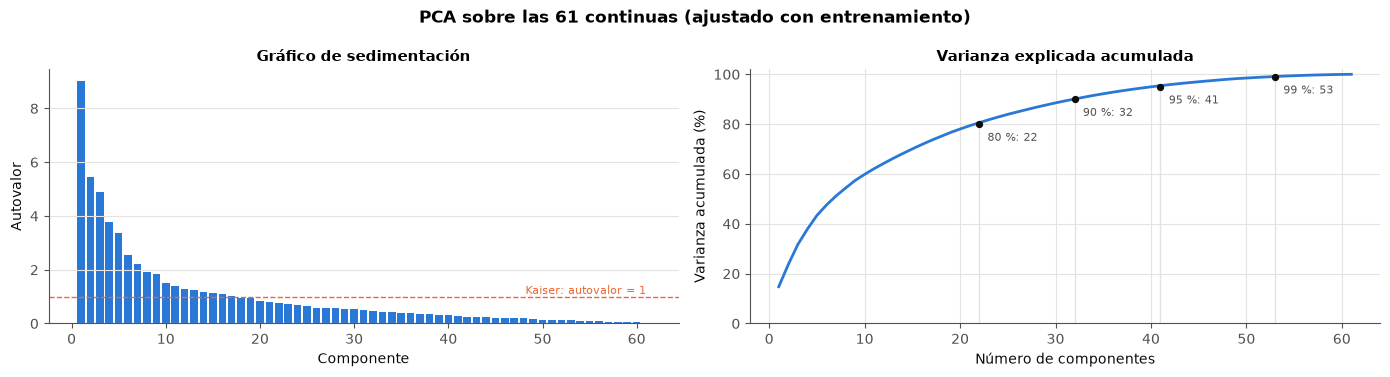

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(1, pca.n_components_ + 1)

ax1.bar(x, varianza['autovalor'], color=AZUL, width=0.8)
ax1.axhline(1, color=NARANJA, linestyle='--', linewidth=1)
ax1.text(pca.n_components_, 1, 'Kaiser: autovalor = 1', ha='right', va='bottom', fontsize=8, color=NARANJA)
ax1.set_xlabel('Componente')
ax1.set_ylabel('Autovalor')
ax1.set_title('Gráfico de sedimentación')
ax1.grid(axis='x', visible=False)

ax2.plot(x, varianza['acumulada_%'], color=AZUL, linewidth=2)
for u, k in componentes_para.items():
    ax2.plot([k, k], [0, u], color=REJILLA, linewidth=1, zorder=0)
    ax2.scatter([k], [u], color=TINTA, s=18, zorder=3)
    ax2.annotate(f'{u} %: {k}', (k, u), textcoords='offset points', xytext=(6, -12), fontsize=8, color=TINTA_2)
ax2.set_ylim(0, 102)
ax2.set_xlabel('Número de componentes')
ax2.set_ylabel('Varianza acumulada (%)')
ax2.set_title('Varianza explicada acumulada')

fig.suptitle(f'PCA sobre las {len(continuas)} continuas (ajustado con entrenamiento)', fontweight='bold')
fig.tight_layout()
guardar(fig, 'pca_varianza_explicada.png')
plt.show()

**Lectura:** la varianza está repartida. El primer componente explica solo un 15 % y no hay un codo claro en el gráfico de sedimentación. Hacen falta 22 componentes para el 80 %, 32 para el 90 % y 41 para el 95 %. Kaiser se queda con 17.

Esto se explica por cómo quedaron los datos tras los issues 3 y 6: ya se eliminaron los pares casi idénticos (correlación ≥ 0.9), así que las 61 columnas restantes aportan bastante información propia. PCA no tiene mucha redundancia lineal que comprimir.

## 3. Cargas de los primeros componentes

Las cargas son los coeficientes de cada variable original en un componente. Se muestran las variables con mayor carga absoluta en los cinco primeros componentes para darles una interpretación.

In [6]:
cargas = pd.DataFrame(pca.components_.T, index=continuas, columns=nombres_pc)

def top_cargas(componente, n=6):
    s = cargas[componente]
    orden = s.abs().sort_values(ascending=False).index[:n]
    return ', '.join(f'{col} ({s[col]:+.2f})' for col in orden)

pd.DataFrame({
    'varianza_%': varianza.loc[nombres_pc[:5], 'varianza_%'].round(1),
    'variables con mayor carga': [top_cargas(pc) for pc in nombres_pc[:5]],
})

,varianza_%,variables con mayor carga
PC1,14.8,"open_acc (+0.26), num_op_rev_tl (+0.26), num_r..."
PC2,8.9,"mo_sin_rcnt_rev_tl_op (+0.24), revol_bal (+0.2..."
PC3,8.0,"all_util (+0.26), num_il_tl (+0.25), open_act_..."
PC4,6.2,"bc_util (+0.36), revol_util (+0.34), percent_b..."
PC5,5.5,"delinq_2yrs (+0.43), mths_since_last_delinq (-..."


Figura guardada en reports/figures/pca_cargas.png


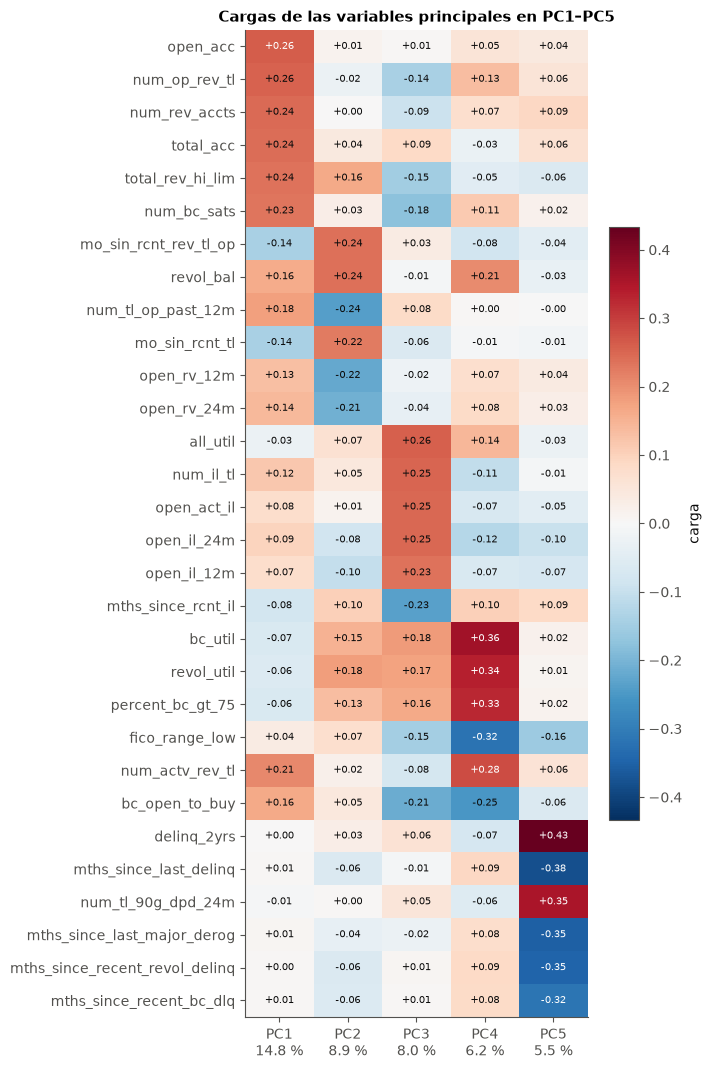

In [7]:
PRIMEROS = nombres_pc[:5]
seleccion = sorted({col for pc in PRIMEROS for col in cargas[pc].abs().nlargest(6).index},
                   key=lambda col: (cargas.loc[col, PRIMEROS].abs().values.argmax(), -cargas.loc[col, PRIMEROS].abs().max()))
datos = cargas.loc[seleccion, PRIMEROS]

fig, ax = plt.subplots(figsize=(7, 0.32 * len(seleccion) + 1.2))
lim = np.abs(datos.values).max()
im = ax.imshow(datos.values, cmap='RdBu_r', norm=TwoSlopeNorm(0, -lim, lim), aspect='auto')
ax.set_xticks(range(len(PRIMEROS)), [f'{pc}\n{varianza.loc[pc, "varianza_%"]:.1f} %' for pc in PRIMEROS])
ax.set_yticks(range(len(seleccion)), seleccion)
for i in range(len(seleccion)):
    for j in range(len(PRIMEROS)):
        v = datos.values[i, j]
        ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(v) > 0.6 * lim else TINTA)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.6, label='carga')
ax.set_title('Cargas de las variables principales en PC1–PC5')
fig.tight_layout()
guardar(fig, 'pca_cargas.png')
plt.show()

**Interpretación de los cinco primeros componentes:**

| Componente | Variables con mayor carga | Lectura |
|---|---|---|
| PC1 (≈15 %) | `open_acc`, `num_op_rev_tl`, `num_rev_accts`, `total_acc`, `total_rev_hi_lim`, `num_bc_sats` (todas +) | **Tamaño del historial crediticio:** cuántas cuentas tiene el solicitante y cuánto crédito rotativo le dieron. |
| PC2 (≈9 %) | `mo_sin_rcnt_rev_tl_op`, `revol_bal`, `mo_sin_rcnt_tl` (+) frente a `num_tl_op_past_12m`, `open_rv_12m`, `open_rv_24m` (−) | **Actividad reciente:** opone a quien abrió cuentas hace poco con quien lleva tiempo sin abrir ninguna. |
| PC3 (≈8 %) | `all_util`, `num_il_tl`, `open_act_il`, `open_il_24m`, `open_il_12m` (+), `mths_since_rcnt_il` (−) | **Préstamos a plazos (installment):** cantidad y uso de créditos no rotativos. |
| PC4 (≈6 %) | `bc_util`, `revol_util`, `percent_bc_gt_75` (+) frente a `fico_range_low`, `bc_open_to_buy` (−) | **Uso del crédito rotativo frente al puntaje FICO:** tarjetas cerca del límite y FICO bajo. Es el perfil de riesgo clásico. |
| PC5 (≈5 %) | `delinq_2yrs`, `num_tl_90g_dpd_24m` (+) frente a los `mths_since_*delinq*` y `mths_since_last_major_derog` (−) | **Morosidad pasada:** atrasos recientes y pocos meses desde el último. |

Los componentes tienen sentido crediticio, pero el de más varianza (PC1, tamaño del historial) no es el más relacionado con el riesgo. La siguiente sección lo mide.

## 4. ¿Los componentes con más varianza son los que más predicen?

Para cada componente se calcula, en entrenamiento, su ROC-AUC univariado frente a `Charged Off`. Se toma `max(AUC, 1 − AUC)` porque el signo de un componente es arbitrario. Un valor de 0.5 significa que el componente, por sí solo, no separa las clases.

In [8]:
Z_ent = pd.DataFrame(pca.transform(X_ent), columns=nombres_pc, index=X_ent.index)
Z_val = pd.DataFrame(pca.transform(X_val_num), columns=nombres_pc, index=X_val_num.index)

auc_ent = Z_ent.apply(lambda z: roc_auc_score(y_train, z))
varianza['auc_univariado'] = np.maximum(auc_ent, 1 - auc_ent)
varianza['rango_auc'] = varianza['auc_univariado'].rank(ascending=False).astype(int)

print('Componentes con mayor AUC univariado en entrenamiento:')
varianza.sort_values('auc_univariado', ascending=False).head(10)[['varianza_%', 'auc_univariado']].round(3)

Componentes con mayor AUC univariado en entrenamiento:


,varianza_%,auc_univariado
PC4,6.171,0.587
PC25,1.068,0.562
PC2,8.908,0.559
PC28,0.938,0.547
PC3,8.027,0.541
PC5,5.497,0.538
PC23,1.190,0.536
PC8,3.169,0.534
PC33,0.727,0.533
PC30,0.854,0.532


Figura guardada en reports/figures/pca_varianza_vs_auc.png


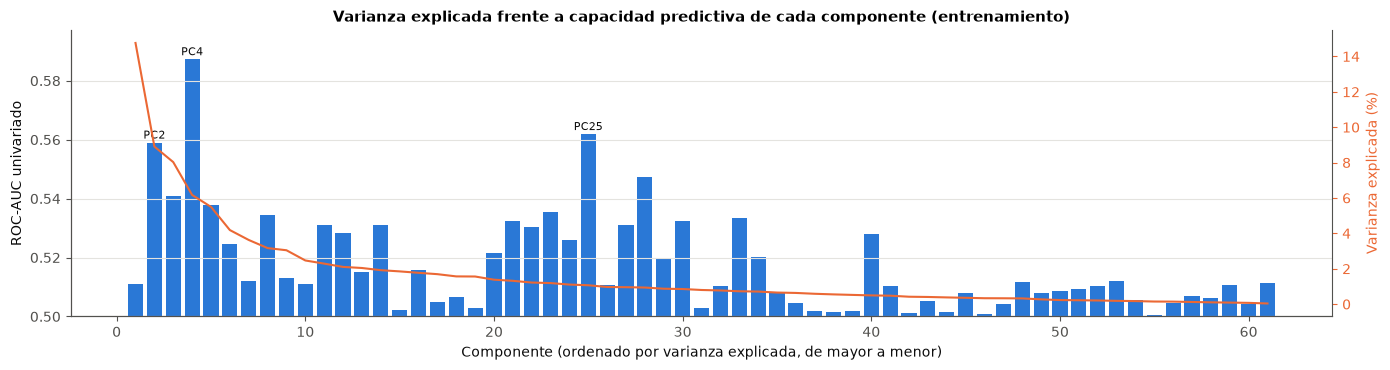

In [9]:
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.bar(x, varianza['auc_univariado'] - 0.5, bottom=0.5, color=AZUL, width=0.8, label='AUC univariado')
ax.set_ylim(0.5, varianza['auc_univariado'].max() + 0.01)
ax.set_xlabel('Componente (ordenado por varianza explicada, de mayor a menor)')
ax.set_ylabel('ROC-AUC univariado')
ax.grid(axis='x', visible=False)
for pc in varianza['auc_univariado'].nlargest(3).index:
    k = nombres_pc.index(pc) + 1
    ax.annotate(pc, (k, varianza.loc[pc, 'auc_univariado']), textcoords='offset points', xytext=(0, 3),
                ha='center', fontsize=8, color=TINTA)
ax2 = ax.twinx()
ax2.plot(x, varianza['varianza_%'], color=NARANJA, linewidth=1.5, label='varianza explicada')
ax2.set_ylabel('Varianza explicada (%)', color=NARANJA)
ax2.tick_params(axis='y', colors=NARANJA)
ax2.grid(False)
ax2.spines['right'].set_visible(True)
ax.set_title('Varianza explicada frente a capacidad predictiva de cada componente (entrenamiento)')
fig.tight_layout()
guardar(fig, 'pca_varianza_vs_auc.png')
plt.show()

**Lectura:** la capacidad predictiva no sigue a la varianza. PC4 (uso del crédito frente a FICO) es el componente más predictivo, aunque solo explica un 6 % de la varianza. PC1, el de más varianza, tiene un AUC prácticamente de 0.50: no separa las clases. Además, aparecen componentes "menores" entre los más predictivos, como PC25 (segundo en AUC), que explica apenas un 1 % de la varianza y está dominado por `open_act_il`, `loan_amnt` y `dti`.

Esto anticipa el problema de PCA en este proyecto: si se corta por varianza acumulada, se pueden descartar justamente direcciones con señal sobre el target.

## 5. Comparación en validación

Se entrena la misma regresión logística del baseline (`max_iter=1000`, `random_state=SEED`) con:

- **Referencia de la cadena:** las 109 numéricas tal como salen del Issue 6. Debe reproducir el valor elegido en el Issue 6.
- **Referencia deduplicada:** las 61 continuas más los 24 indicadores únicos. Comprueba que quitar las copias exactas no cambia nada.
- **PCA, primeros k componentes + indicadores:** el uso habitual, cortando por varianza. Se prueban varios valores de k, incluidos los de los umbrales de varianza y de Kaiser.
- **PCA, k componentes elegidos por AUC univariado + indicadores:** ordena los componentes por su relación con el target en entrenamiento en lugar de por varianza. Sirve para ver cuánto se pierde por cortar solo por varianza.
- **Control: PCA sobre continuas e indicadores juntos**, primeros k componentes.

Las categóricas no entran en ninguno de los casos, así que la comparación es justa entre sí; los valores no son comparables con un modelo que sí las use.

In [10]:
def evaluar(X_ajuste, X_eval):
    modelo = LogisticRegression(max_iter=1000, random_state=SEED)
    inicio = time.time()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', ConvergenceWarning)
        modelo.fit(X_ajuste, y_train)
    prob = modelo.predict_proba(X_eval)[:, 1]
    return {
        'ROC-AUC': roc_auc_score(y_val, prob),
        'PR-AUC': average_precision_score(y_val, prob),
        'iteraciones': int(modelo.n_iter_[0]),
        'convergió': not any(issubclass(a.category, ConvergenceWarning) for a in avisos),
        'segundos': round(time.time() - inicio, 1),
    }

def con_indicadores(Z_a, Z_b):
    return np.hstack([Z_a, I_ent]), np.hstack([Z_b, I_val])

referencia_cadena = evaluar(X_train[numericas_cadena], X_val[numericas_cadena])
referencia = evaluar(*con_indicadores(X_ent.to_numpy(), X_val_num.to_numpy()))
n_ref = len(continuas) + len(indicadores_unicos)

# PCA de control: continuas + indicadores únicos
X_ent_ctrl = np.hstack([X_ent.to_numpy(), I_ent])
X_val_ctrl = np.hstack([X_val_num.to_numpy(), I_val])
pca_ctrl = PCA(random_state=SEED).fit(X_ent_ctrl)
acum_ctrl = pca_ctrl.explained_variance_ratio_.cumsum() * 100
kaiser_ctrl = int((pca_ctrl.explained_variance_ > 1).sum())
para_ctrl = {u: int(np.searchsorted(acum_ctrl, u) + 1) for u in UMBRALES}
Zc_ent, Zc_val = pca_ctrl.transform(X_ent_ctrl), pca_ctrl.transform(X_val_ctrl)

VALORES_K = sorted({5, 10, 15, kaiser, 20, 25, 30, 35, *componentes_para.values(), 45, 50, 55, len(continuas)})
por_auc = list(varianza.sort_values('auc_univariado', ascending=False).index)

filas = [
    {'método': 'Sin PCA: cadena (109)', 'k': len(numericas_cadena), 'varianza_%': 100.0, **referencia_cadena},
    {'método': 'Sin PCA: deduplicada (referencia)', 'k': n_ref, 'varianza_%': 100.0, **referencia},
]
for k in VALORES_K:
    filas.append({'método': 'PCA: primeros k', 'k': k, 'varianza_%': varianza['acumulada_%'].iloc[k - 1],
                  **evaluar(*con_indicadores(Z_ent.iloc[:, :k].to_numpy(), Z_val.iloc[:, :k].to_numpy()))})
    columnas = por_auc[:k]
    filas.append({'método': 'PCA: k por AUC', 'k': k, 'varianza_%': varianza.loc[columnas, 'varianza_%'].sum(),
                  **evaluar(*con_indicadores(Z_ent[columnas].to_numpy(), Z_val[columnas].to_numpy()))})
for k in sorted({10, 20, kaiser_ctrl, 30, 40, *para_ctrl.values(), 60, 70, n_ref}):
    filas.append({'método': 'Control: PCA con indicadores', 'k': k, 'varianza_%': acum_ctrl[k - 1],
                  **evaluar(Zc_ent[:, :k], Zc_val[:, :k])})
comparacion = pd.DataFrame(filas)
comparacion['Δ ROC-AUC'] = comparacion['ROC-AUC'] - referencia['ROC-AUC']
comparacion['Δ PR-AUC'] = comparacion['PR-AUC'] - referencia['PR-AUC']
print(f'PCA de control ({X_ent_ctrl.shape[1]} columnas): Kaiser {kaiser_ctrl}; ' +
      ', '.join(f'{u} % -> {k}' for u, k in para_ctrl.items()))
print('En "PCA: ..." la columna k cuenta solo componentes; el modelo usa además los '
      f'{len(indicadores_unicos)} indicadores únicos.')
comparacion.set_index(['método', 'k']).round(4)

PCA de control (85 columnas): Kaiser 21; 80 % -> 23, 90 % -> 36, 95 % -> 46, 99 % -> 64
En "PCA: ..." la columna k cuenta solo componentes; el modelo usa además los 24 indicadores únicos.


,,varianza_%,ROC-AUC,PR-AUC,iteraciones,convergió,segundos,Δ ROC-AUC,Δ PR-AUC
método,k,,,,,,,,
Sin PCA: cadena (109),109,100.0000,0.6883,0.3468,50,True,3.9,0.0000,0.0000
Sin PCA: deduplicada (referencia),85,100.0000,0.6883,0.3468,40,True,2.3,0.0000,0.0000
PCA: primeros k,5,43.3660,0.6335,0.2892,31,True,1.1,-0.0548,-0.0576
PCA: k por AUC,5,25.1129,0.6507,0.3057,28,True,0.9,-0.0376,-0.0411
PCA: primeros k,10,59.8621,0.6387,0.2958,32,True,1.2,-0.0496,-0.0510
PCA: k por AUC,10,36.5499,0.6640,0.3190,32,True,1.3,-0.0243,-0.0278
PCA: primeros k,15,70.0687,0.6466,0.3014,37,True,1.6,-0.0417,-0.0453
PCA: k por AUC,15,44.2540,0.6739,0.3298,32,True,1.3,-0.0144,-0.0170
PCA: primeros k,17,73.5328,0.6466,0.3015,37,True,1.6,-0.0417,-0.0453


Figura guardada en reports/figures/pca_comparacion_validacion.png


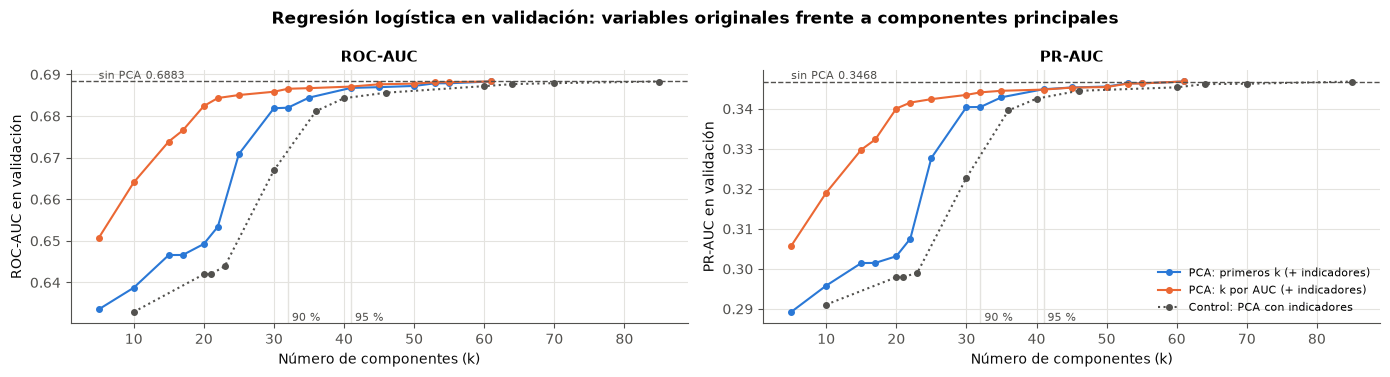

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 3.8), sharex=True)
for ax, metrica in zip(ejes, ['ROC-AUC', 'PR-AUC']):
    for metodo, color in (('PCA: primeros k', AZUL), ('PCA: k por AUC', NARANJA),
                          ('Control: PCA con indicadores', TINTA_2)):
        datos = comparacion[comparacion['método'] == metodo]
        ax.plot(datos['k'], datos[metrica], color=color, marker='o', markersize=4, linewidth=1.5,
                label=metodo + (' (+ indicadores)' if metodo.startswith('PCA') else ''),
                linestyle=':' if metodo.startswith('Control') else '-')
    ax.axhline(referencia[metrica], color=TINTA_2, linestyle='--', linewidth=1)
    ax.text(5, referencia[metrica], f'sin PCA {referencia[metrica]:.4f}', ha='left', va='bottom', fontsize=8, color=TINTA_2)
    for u, k in componentes_para.items():
        if u in (90, 95):
            ax.axvline(k, color=REJILLA, linewidth=1, zorder=0)
            ax.text(k, ax.get_ylim()[0], f' {u} %', fontsize=8, color=TINTA_2, va='bottom')
    ax.set_xlabel('Número de componentes (k)')
    ax.set_ylabel(f'{metrica} en validación')
    ax.set_title(metrica)
ejes[1].legend(loc='lower right', frameon=False, fontsize=8)
fig.suptitle('Regresión logística en validación: variables originales frente a componentes principales', fontweight='bold')
fig.tight_layout()
guardar(fig, 'pca_comparacion_validacion.png')
plt.show()

**Lectura:**

- **Las copias de los indicadores no cambian nada.** Las 109 numéricas de la cadena y la versión deduplicada (61 continuas + 24 indicadores) dan exactamente el mismo resultado (ROC-AUC 0.6883, PR-AUC 0.3468), que coincide con el elegido en el Issue 6. Una columna repetida no añade información a la regresión logística.
- **Ningún k mejora a las variables originales.** Con todos los componentes, el resultado es idéntico al de referencia: es solo una rotación de los mismos datos, y la regresión logística es invariante a rotaciones. Cortando por varianza, cualquier k menor pierde rendimiento.
- **Cortar por varianza cuesta caro con pocos componentes.** Con el criterio de Kaiser (17 componentes, 73.5 % de la varianza) el ROC-AUC cae de 0.6883 a 0.6466 y el PR-AUC de 0.3468 a 0.3015. Con 41 componentes (95 % de la varianza) la pérdida es pequeña (−0.0015 de ROC-AUC), pero solo se ahorran 20 columnas.
- **El salto entre k = 22 y k = 25** (0.6534 → 0.6708) coincide con la entrada de PC25, uno de los componentes más predictivos pese a su baja varianza (sección 4).
- **Ordenar por AUC recupera la señal antes** (con 20 componentes: 0.6824 frente a 0.6493), lo que confirma que el problema es el criterio de varianza y no la información. Aun así, nunca supera a la referencia; desde k ≈ 50 la diferencia es de −0.0005 o menos, y para entonces ya casi no reduce dimensiones. Además, esa variante ya no es PCA "puro": usa el target para elegir.
- **Meter los indicadores en el PCA empeora el corte por varianza.** En el control (PCA sobre 85 columnas), Kaiser se queda con 21 componentes y da 0.6420; hacen falta 46 componentes para el 95 % (0.6856). Los indicadores son binarios y muy correlacionados entre sí, así que ocupan componentes de alta varianza que no aportan señal nueva.

Una ventaja menor de PCA es que la regresión logística converge en menos iteraciones, porque los componentes son ortogonales. Con estos tamaños el modelo entrena en pocos segundos de todos modos, así que no compensa la pérdida.

## 6. Por qué no se usa LDA

El profesor recomendó también el análisis discriminante lineal (LDA). LDA, a diferencia de PCA, sí usa el target, pero produce como máximo *(número de clases − 1)* componentes. Con un target binario (`Charged Off` / pagado) eso es **un solo componente**: no sirve como técnica de reducción a varias dimensiones, sino que equivale a un clasificador lineal. Por eso queda fuera del preprocesamiento, como se acordó en el Issue 1.

## 7. Conclusiones

1. **PCA no se usa en el dataset final.** En validación, ningún número de componentes mejora a la regresión logística con las variables originales (ROC-AUC 0.6883, PR-AUC 0.3468, con las 61 continuas y los indicadores de nulo). Con el 95 % de la varianza (41 componentes) se pierden 0.0015 de ROC-AUC y con el criterio de Kaiser, 0.042.
2. **La redundancia lineal ya se eliminó en el Issue 3.** Las continuas reparten la varianza (PC1 ≈ 15 %, 41 componentes para el 95 %), así que PCA comprime poco.
3. **Varianza no es poder predictivo.** El componente más predictivo es PC4 (uso del crédito frente a FICO), y PC25, con apenas un 1 % de la varianza, es el segundo; PC1 no separa las clases. Cortar por varianza descarta señal.
4. **Los indicadores de nulo no deben entrar al PCA.** De los 48 solo 24 son distintos; incluso deduplicados, al meterlos en el PCA hacen falta más componentes para la misma varianza y el corte de Kaiser rinde peor. Si en algún momento se usa PCA, conviene ajustarlo solo sobre las continuas y dejar pasar los indicadores únicos.
5. **Se pierde interpretabilidad.** Las variables originales (`fico_range_low`, `revol_util`, `dti`) se explican directamente en un modelo de riesgo; los componentes, no.
6. **El análisis sigue siendo útil para el informe:** los cinco primeros componentes resumen la estructura de los datos (tamaño del historial, actividad reciente, préstamos a plazos, uso del crédito frente a FICO y morosidad pasada).

**Cuándo revisar esta decisión:** si se prueban modelos sensibles a la dimensión o a la colinealidad (por ejemplo, k-NN o SVM con kernel), puede valer la pena repetir la comparación con ellos. El objeto `pca` y la tabla `comparacion` quedan disponibles al ejecutar este notebook.

**Pendiente de la cadena que afecta a este resultado:** la cadena entrega `loan_amnt` entre las numéricas (Issue 2, `incluir_condicionales=True`), aunque la propuesta lo deja como condicional. Hay que confirmar con el equipo si entra; aparece con carga alta en PC25.

## Salida

PCA no se aplica: `X_train`, `X_val` y `X_test` salen de este notebook **sin cambios** respecto de `issue6.ipynb`, con los 48 indicadores de nulo incluidos. La deduplicación de indicadores se usó solo para ajustar el PCA; la regresión logística da el mismo resultado con o sin las copias (sección 5). Son el dataset final para los modelos: numéricas tratadas por los issues 5 y 6 y categóricas aún sin codificar (pendiente para el modelado).

In [12]:
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
assert X_train[continuas].equals(X_ent), 'Este notebook no debe modificar X_train'
print(f'X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}')

X_train: (862757, 117) | X_val: (215690, 117) | X_test: (269612, 117)
